# Classifying cultural relevance: full recipe collection

Adapted from HW3 (classification as sensemaking) for the full collection of 300 hand-labeled recipes.

**The split** (made once by `make_split.py`, seed 202, stratified on the 0-5 cultural relevance score):

| part | file | recipes | used for |
|---|---|---|---|
| train (80%) | `data/train.json` | 240 | training, and cross-validation for Parts 3-6 |
| tune (10%) | `data/tune.json` | 30 | choosing settings (C, n-grams, min_df) |
| **holdout (10%)** | `data/holdout/` | 30 | **sealed: final evaluation only** |

**The holdout folder is never loaded by this notebook** (or by any other experiment) until the final-evaluation cell at the very end is switched on, after tuning is completely done.

## Part 0: Setup

In [1]:
import json
import os
from collections import Counter

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import ConfusionMatrixDisplay, accuracy_score, classification_report, confusion_matrix, f1_score
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.pipeline import Pipeline

pd.set_option("display.max_colwidth", 250)
pd.set_option("display.width", 200)

## Part 1: Load the train and tune recipes

`TARGET` picks what the classifier predicts:

* `"cr_binary"` (default, like HW3): cultural relevance 0-2 = **not culturally relevant**, 3-5 = **culturally relevant**
* `"cr_score"`: the full 0-5 score as six classes
* `"region"`: the first cuisine tag (Americas, Europe, Asia, ...); recipes with no cuisine tag are "none", and regions with fewer than `MIN_REGION` train recipes become "Other"

In [2]:
TARGET = "cr_binary"      # "cr_binary", "cr_score", or "region"
CR_THRESHOLD = 3          # cr_binary: scores >= this count as culturally relevant
MIN_REGION = 5            # region: smaller regions are grouped into "Other"
RANDOM_STATE = 0

DATA_DIR = "data"         # holds train.json and tune.json; the holdout/ subfolder is NOT read here

In [3]:
def recipe_text(r):
    """Title, description, ingredient names and steps joined into one string."""
    parts = [r.get("title"), r.get("description")]
    parts += [i.get("item") for i in r.get("ingredients") or []]
    parts += r.get("steps") or []
    return " ".join(p for p in parts if p).replace("\t", " ").replace("\n", " ")

REGION_FIX = {"Asian": "Asia", "African": "Africa", "North African": "Africa", "European": "Europe", "Indian": "Asia"}

def raw_label(r):
    if TARGET == "cr_binary":
        score = r["cultural relevance"]["score"]
        return "culturally relevant" if score >= CR_THRESHOLD else "not culturally relevant"
    if TARGET == "cr_score":
        return str(r["cultural relevance"]["score"])
    if TARGET == "region":
        tags = (r.get("source_tags") or {}).get("cuisine") or []
        return REGION_FIX.get(tags[0], tags[0]) if tags else "none"
    raise ValueError("TARGET must be cr_binary, cr_score or region")

def load(name):
    recipes = json.load(open(os.path.join(DATA_DIR, name), encoding="utf-8"))
    return pd.DataFrame({"id": [r["id"] for r in recipes],
                         "title": [r["title"] for r in recipes],
                         "label": [raw_label(r) for r in recipes],
                         "text": [recipe_text(r) for r in recipes]})

df = load("train.json")        # 240 recipes
tune_df = load("tune.json")    # 30 recipes

if TARGET == "region":         # group small regions, using train counts only
    keep = {l for l, n in Counter(df.label).items() if n >= MIN_REGION}
    df["label"] = [l if l in keep else "Other" for l in df.label]
    tune_df["label"] = [l if l in keep else "Other" for l in tune_df.label]

print(len(df), "train recipes,", len(tune_df), "tune recipes")

240 train recipes, 30 tune recipes


### Look at your data (train only)

In [4]:
print(df.label.value_counts())
print()
for label in sorted(df.label.unique()):
    print("==", label)
    sub = df[df.label == label]
    for _, row in sub.sample(min(3, len(sub)), random_state=RANDOM_STATE).iterrows():
        print("   ", row.id, row.text[:200])

label
culturally relevant        130
not culturally relevant    110
Name: count, dtype: int64

== culturally relevant
    r0017 Mooncakes, a Classic Recipe (Cantonese Mooncakes) Nothing can beat the taste of homemade mooncakes. This recipe shows you how to make traditional mooncakes with easy steps. dried lotus seeds sugar oil
    r0112 Shawarma Salad Everything you love about a shawarma (well, apart from the traditional meaty filling), but in salad form. Crispy smoked tofu strips, meaty roasted mushrooms, a harissa tahini yoghurt, c
    r0212 Classic Pumpkin Pie Our Favorite Pie Crust all-purpose flour large eggs solid-pack pumpkin heavy cream light brown sugar whole milk ground cinnamon ground ginger kosher salt ground cloves Sweetened Wh
== not culturally relevant
    r0264 Warmed Spiced Olives fennel seeds lemon zest dried bay leaves mixed unpitted olives olive oil Aleppo pepper Toast fennel seeds in a large skillet over medium heat, stirring occasionally, until fragran
    r0053 E

## Part 2: Tune on the tune set

Each combination of settings is trained on the 240 train recipes and scored on the 30 tune recipes. The tune set is small, so one recipe changes accuracy by about 3 points: treat small differences as ties and prefer the simpler setting. Copy the settings you choose into the next cell.

In [5]:
def make_model(ngram_range=(1, 1), min_df=2, C=1.0):
    return Pipeline([
        ("vec", CountVectorizer(lowercase=True, binary=True, ngram_range=ngram_range, min_df=min_df,
                                token_pattern=r"[A-Za-z0-9']+")),
        ("clf", LogisticRegression(C=C, solver="lbfgs", max_iter=10000)),
    ])

X_tr, y_tr = df.text.to_list(), np.array(df.label.to_list())
X_tu, y_tu = tune_df.text.to_list(), np.array(tune_df.label.to_list())

grid = []
for ngram_range in [(1, 1), (1, 2)]:
    for min_df in [1, 2, 3]:
        for C in [0.01, 0.1, 1.0, 10.0]:
            m = make_model(ngram_range, min_df, C).fit(X_tr, y_tr)
            p = m.predict(X_tu)
            grid.append({"ngram_range": ngram_range, "min_df": min_df, "C": C,
                         "tune accuracy": accuracy_score(y_tu, p),
                         "tune macro F1": f1_score(y_tu, p, average="macro", zero_division=0)})
grid = pd.DataFrame(grid).sort_values(["tune macro F1", "tune accuracy"], ascending=False)
display(grid.round(3).reset_index(drop=True))

majority = Counter(y_tr).most_common(1)[0][0]
print("Tune-set majority baseline (always '%s'): %.3f" % (majority, (y_tu == majority).mean()))

,ngram_range,min_df,C,tune accuracy,tune macro F1
0,"(1, 1)",1,0.01,0.800,0.799
1,"(1, 1)",2,0.01,0.800,0.799
2,"(1, 1)",3,0.01,0.800,0.799
3,"(1, 2)",1,0.01,0.800,0.799
4,"(1, 2)",2,0.01,0.800,0.799
5,"(1, 2)",3,0.01,0.800,0.799
6,"(1, 1)",1,0.10,0.767,0.766
7,"(1, 1)",2,0.10,0.767,0.766
8,"(1, 1)",3,0.10,0.767,0.766
9,"(1, 2)",1,10.00,0.767,0.766


Tune-set majority baseline (always 'culturally relevant'): 0.533


In [6]:
# Your chosen settings (HW3 defaults to start)
NGRAM_RANGE = (1, 1)
MIN_DF = 2
C = 1.0
N_FOLDS = 5

model = make_model(NGRAM_RANGE, MIN_DF, C).fit(X_tr, y_tr)
tune_pred = model.predict(X_tu)
print("Tune accuracy with chosen settings: %.3f" % accuracy_score(y_tu, tune_pred))
display(pd.DataFrame(classification_report(y_tu, tune_pred, output_dict=True, zero_division=0)).T.round(3))
tune_df["pred"] = tune_pred
display(tune_df[tune_df.label != tune_df.pred][["id", "title", "label", "pred"]])

Tune accuracy with chosen settings: 0.733


,precision,recall,f1-score,support
culturally relevant,0.786,0.688,0.733,16.000
not culturally relevant,0.688,0.786,0.733,14.000
accuracy,0.733,0.733,0.733,0.733
macro avg,0.737,0.737,0.733,30.000
weighted avg,0.740,0.733,0.733,30.000


,id,title,label,pred
5,r0037,Plátanos Horneados con Crema y Queso (Baked Banana With Crema and Cheese),culturally relevant,not culturally relevant
6,r0039,Pork Chops and Padrón Chiles en Escabèche,not culturally relevant,culturally relevant
9,r0074,One-Pot Spicy Halal Cart Chicken over Rice,culturally relevant,not culturally relevant
15,r0157,Buckwheat Porridge with Maple Cinnamon Caramelized Bananas,culturally relevant,not culturally relevant
16,r0172,Beer-Steamed Clams,not culturally relevant,culturally relevant
17,r0178,Grapefruit Chermoula,culturally relevant,not culturally relevant
25,r0273,Butternut Squash Vegducken,culturally relevant,not culturally relevant
29,r0290,Torn Potatoes of Many Colors With Chile-Lime Butter,not culturally relevant,culturally relevant


## Part 3: Cross-validated predictions on the train set

As in HW3, every train recipe gets a prediction from a model that never saw it, so Parts 4-6 can look at all 240. (This uses only the train set.)

In [7]:
X, y = X_tr, y_tr
classes = np.unique(y)
n_splits = min(N_FOLDS, Counter(y).most_common()[-1][1])
assert n_splits >= 2, "Need at least 2 examples of every class"

cv = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=RANDOM_STATE)
probs = cross_val_predict(make_model(NGRAM_RANGE, MIN_DF, C), X, y, cv=cv, method="predict_proba")
pred = classes[probs.argmax(axis=1)]

class_index = {c: i for i, c in enumerate(classes)}
df["pred"] = pred
df["p_true"] = [probs[i, class_index[l]] for i, l in enumerate(df.label)]
df["p_pred"] = probs.max(axis=1)

majority = Counter(y).most_common(1)[0]
print("Majority class baseline: %.3f (%s)" % (majority[1] / len(y), majority[0]))
print("Cross-validated accuracy: %.3f" % (pred == y).mean())
report = pd.DataFrame(classification_report(y, pred, output_dict=True, zero_division=0)).T
display(report.loc[list(classes) + ["macro avg"], ["precision", "recall", "f1-score", "support"]].round(3))

Majority class baseline: 0.542 (culturally relevant)
Cross-validated accuracy: 0.658


,precision,recall,f1-score,support
culturally relevant,0.679,0.700,0.689,130.0
not culturally relevant,0.632,0.609,0.620,110.0
macro avg,0.656,0.655,0.655,240.0


## Part 4: What features characterize each class?

One model trained on all 240 train recipes; the highest-weighted words for each class.

In [8]:
final_model = make_model(NGRAM_RANGE, MIN_DF, C).fit(X, y)
vec, clf = final_model.named_steps["vec"], final_model.named_steps["clf"]
feature_names = np.array(vec.get_feature_names_out())

if len(classes) == 2:
    W = np.vstack([-clf.coef_[0], clf.coef_[0]])
else:
    W = clf.coef_

def top_features(n=15):
    return pd.DataFrame({c: [f"{feature_names[j]} ({W[i, j]:.2f})" for j in np.argsort(-W[i])[:n]]
                         for i, c in enumerate(classes)})

display(top_features(15))

,culturally relevant,not culturally relevant
0,at (0.66),cheese (0.63)
1,fresh (0.55),brown (0.60)
2,finely (0.54),top (0.53)
3,the (0.44),from (0.47)
4,red (0.43),down (0.46)
5,classic (0.42),seed (0.46)
6,4 (0.41),olive (0.45)
7,roughly (0.40),side (0.41)
8,thanksgiving (0.39),cool (0.41)
9,or (0.39),pumpkin (0.40)


In [9]:
def where(feature, label=None, k=5):
    '''Train recipes that contain `feature` (optionally only those with human label `label`).'''
    col = vec.transform(df.text)[:, vec.vocabulary_[feature]].toarray().ravel() > 0
    sub = df[col] if label is None else df[col & (df.label == label)]
    display(sub[["id", "title", "label", "pred"]].head(k))

# e.g. where("tortilla")

## Part 5: Which classes overlap? (confusion matrix, train cross-validation)

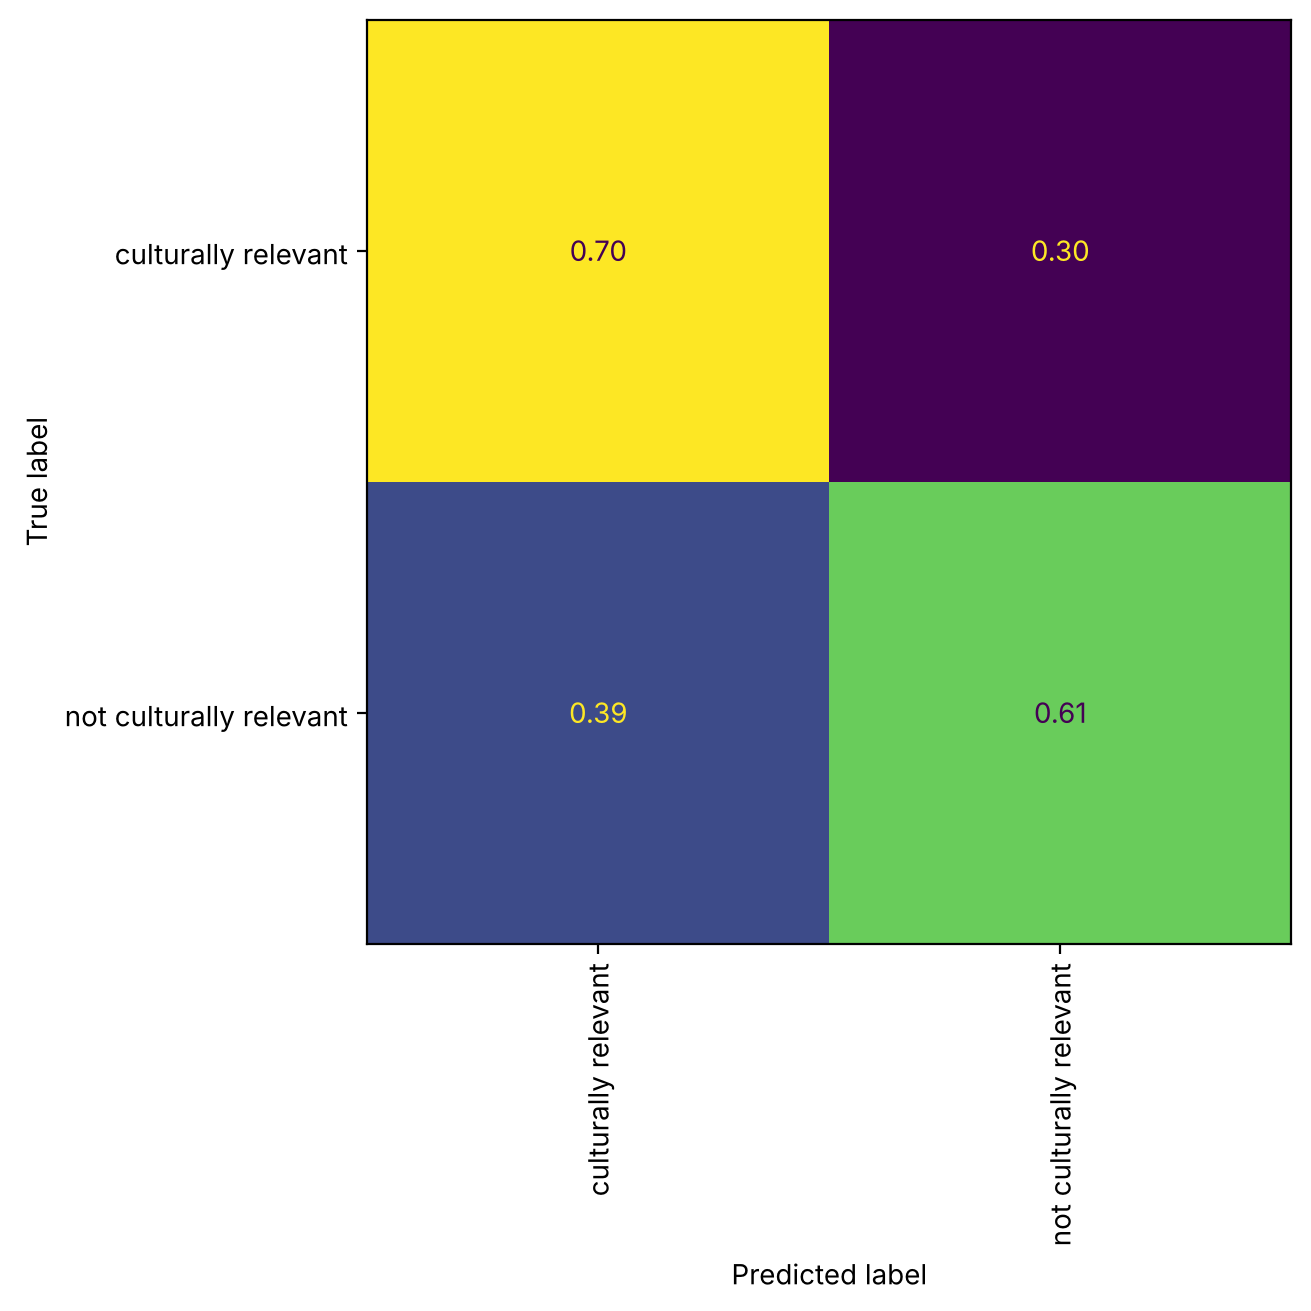

,A,B,A->B (n),A->B (rate),B->A (n),B->A (rate),total
0,culturally relevant,not culturally relevant,39,0.3,43,0.391,82


In [10]:
size = max(6, 0.6 * len(classes))
fig, ax = plt.subplots(figsize=(size, size))
ConfusionMatrixDisplay.from_predictions(y, pred, labels=classes, normalize="true", ax=ax,
                                        xticks_rotation="vertical", values_format=".2f", colorbar=False)
plt.show()

cm = confusion_matrix(y, pred, labels=classes)
rows = []
for i, a in enumerate(classes):
    for j, b_ in enumerate(classes):
        if i < j:
            rows.append({"A": a, "B": b_,
                         "A->B (n)": cm[i, j], "A->B (rate)": cm[i, j] / max(cm[i].sum(), 1),
                         "B->A (n)": cm[j, i], "B->A (rate)": cm[j, i] / max(cm[j].sum(), 1)})
pairs = pd.DataFrame(rows)
pairs["total"] = pairs["A->B (n)"] + pairs["B->A (n)"]
display(pairs.sort_values("total", ascending=False).head(15).round(3).reset_index(drop=True))

In [11]:
def confused(a, b_, k=8):
    '''Train recipes with true label `a` that the model predicted as `b_`, most confident first.'''
    sub = df[(df.label == a) & (df.pred == b_)].sort_values("p_pred", ascending=False).head(k)
    display(sub[["id", "title", "label", "pred", "p_pred"]].round(3))

if TARGET == "cr_binary":
    confused("not culturally relevant", "culturally relevant")
    confused("culturally relevant", "not culturally relevant")

,id,title,label,pred,p_pred
35,r0047,Japanese Chicken Curry,not culturally relevant,culturally relevant,0.981
141,r0173,Chicken Fajitas,not culturally relevant,culturally relevant,0.979
208,r0261,Scotchy Boulevardiers for a Crowd,not culturally relevant,culturally relevant,0.970
225,r0282,Potatoes au Gratin,not culturally relevant,culturally relevant,0.969
234,r0295,Shortcut Puff Pastry,not culturally relevant,culturally relevant,0.956
218,r0272,Butternut Squash Tarte Tatin,not culturally relevant,culturally relevant,0.939
74,r0091,Steak Yuzu Kosho,not culturally relevant,culturally relevant,0.938
26,r0035,Easy Grilled Salmon in Foil With Lemon-Garlic-Herb Butter,not culturally relevant,culturally relevant,0.929


,id,title,label,pred,p_pred
183,r0228,Roasted Carrots and Parsnips With Honey,culturally relevant,not culturally relevant,0.971
146,r0179,Green Mango Salad,culturally relevant,not culturally relevant,0.969
53,r0069,Sheet Pan Chicken Fajitas,culturally relevant,not culturally relevant,0.952
131,r0160,Poutine,culturally relevant,not culturally relevant,0.902
50,r0065,Classic Loco Moco,culturally relevant,not culturally relevant,0.856
126,r0152,Skagen Toast (Skagenröra),culturally relevant,not culturally relevant,0.847
70,r0087,Fennel Salad,culturally relevant,not culturally relevant,0.840
19,r0028,Classic Cacio E Pepe,culturally relevant,not culturally relevant,0.814


## Part 6: Central items and uncertain items

In [12]:
K_CENTRAL = 8
for c in classes:
    print("=" * 20, c, "=" * 20)
    display(df[df.label == c].sort_values("p_true", ascending=False).head(K_CENTRAL)[["id", "title", "label", "p_true"]].round(3))

==================== culturally relevant ====================


,id,title,label,p_true
16,r0023,Pad Thai,culturally relevant,0.999
23,r0032,Chicken Tamales Verdes,culturally relevant,0.993
12,r0019,Chicken 'Cafe de Paris',culturally relevant,0.989
168,r0211,Classic Pecan Pie,culturally relevant,0.989
191,r0238,Turkey for Two With Pan-Sauce Gravy,culturally relevant,0.988
176,r0219,How to Cook a Ham,culturally relevant,0.988
30,r0042,Funeral Potatoes,culturally relevant,0.985
120,r0146,Better for You Banana Bread,culturally relevant,0.981


==================== not culturally relevant ====================


,id,title,label,p_true
229,r0287,Squash and Radicchio Salad With Pecans,not culturally relevant,0.996
147,r0180,Grilled Lettuces with Crème Fraîche and Avocado,not culturally relevant,0.988
137,r0166,Salmon Bowl with Spicy Yogurt Sauce,not culturally relevant,0.983
60,r0077,Pasta with Tuna in the Style of Puttanesca,not culturally relevant,0.982
222,r0279,Herb-Crusted Cauliflower Steaks With Beans and Tomatoes,not culturally relevant,0.969
150,r0185,Linguine with Green Olive Sauce and Zesty Breadcrumbs,not culturally relevant,0.968
39,r0051,Caramelized Onion Pasta,not culturally relevant,0.962
216,r0270,Butternut Squash Steaks With Brown Butter–Sage Sauce,not culturally relevant,0.959


In [13]:
order = np.argsort(-probs, axis=1)
top1, top2 = order[:, 0], order[:, 1]
idx = np.arange(len(df))
df["top1"], df["top2"] = classes[top1], classes[top2]
df["margin"] = probs[idx, top1] - probs[idx, top2]
df["n_known"] = np.asarray((vec.transform(X) > 0).sum(axis=1)).ravel()

print("Most uncertain (smallest margin):")
display(df.sort_values("margin").head(15)[["id", "title", "label", "top1", "top2", "margin", "n_known"]].round(3))

print("Most confident mistakes:")
display(df[df.pred != df.label].sort_values("p_pred", ascending=False).head(20)[["id", "title", "label", "pred", "p_pred", "p_true"]].round(3))

Most uncertain (smallest margin):


,id,title,label,top1,top2,margin,n_known
81,r0100,"Sardines, Smashed Cannellini and Herb Dressing on Rye Bread",not culturally relevant,not culturally relevant,culturally relevant,0.001,73
206,r0258,Parmesan-Roasted Butternut Squash,culturally relevant,culturally relevant,not culturally relevant,0.008,88
56,r0072,Atún Toreado (Tuna with Blistered Chile),not culturally relevant,not culturally relevant,culturally relevant,0.012,50
76,r0093,Courgette and Sausage Pasta,not culturally relevant,culturally relevant,not culturally relevant,0.013,40
118,r0144,Adult Apple Cheddar Caramelized Onion Grilled Cheese,not culturally relevant,not culturally relevant,culturally relevant,0.015,43
102,r0124,From-Scratch Bone Broth Chicken Noodle Soup,not culturally relevant,culturally relevant,not culturally relevant,0.016,178
43,r0055,Lemon Poppy Seed Loaf Cake,not culturally relevant,culturally relevant,not culturally relevant,0.026,239
34,r0046,Hawaiian Style Spam Musubi,culturally relevant,not culturally relevant,culturally relevant,0.040,91
91,r0110,Burrito Salad,culturally relevant,not culturally relevant,culturally relevant,0.047,158
195,r0244,3-Ingredient Caramel Apple Hand Pies,not culturally relevant,not culturally relevant,culturally relevant,0.049,99


Most confident mistakes:


,id,title,label,pred,p_pred,p_true
35,r0047,Japanese Chicken Curry,not culturally relevant,culturally relevant,0.981,0.019
141,r0173,Chicken Fajitas,not culturally relevant,culturally relevant,0.979,0.021
183,r0228,Roasted Carrots and Parsnips With Honey,culturally relevant,not culturally relevant,0.971,0.029
208,r0261,Scotchy Boulevardiers for a Crowd,not culturally relevant,culturally relevant,0.970,0.030
146,r0179,Green Mango Salad,culturally relevant,not culturally relevant,0.969,0.031
225,r0282,Potatoes au Gratin,not culturally relevant,culturally relevant,0.969,0.031
234,r0295,Shortcut Puff Pastry,not culturally relevant,culturally relevant,0.956,0.044
53,r0069,Sheet Pan Chicken Fajitas,culturally relevant,not culturally relevant,0.952,0.048
218,r0272,Butternut Squash Tarte Tatin,not culturally relevant,culturally relevant,0.939,0.061
74,r0091,Steak Yuzu Kosho,not culturally relevant,culturally relevant,0.938,0.062


## Part 7: FINAL EVALUATION (sealed holdout)

**Leave `FINAL_EVAL = False` until tuning is completely finished.** This is the only cell that reads `data/holdout/`. Run it once, with the settings chosen above, and do not tune again afterwards.

In [14]:
FINAL_EVAL = False

if FINAL_EVAL:
    holdout_df = load(os.path.join("holdout", "holdout.json"))
    if TARGET == "region":
        holdout_df["label"] = [l if l in keep else "Other" for l in holdout_df.label]
    # train on train + tune with the chosen settings, then score the holdout once
    full = pd.concat([df[["text", "label"]], tune_df[["text", "label"]]])
    final = make_model(NGRAM_RANGE, MIN_DF, C).fit(full.text.to_list(), full.label.to_list())
    hp = final.predict(holdout_df.text.to_list())
    print("HOLDOUT accuracy: %.3f" % accuracy_score(holdout_df.label, hp))
    display(pd.DataFrame(classification_report(holdout_df.label, hp, output_dict=True, zero_division=0)).T.round(3))
else:
    print("Holdout sealed. Set FINAL_EVAL = True only when tuning is done.")

Holdout sealed. Set FINAL_EVAL = True only when tuning is done.
